#### Definição das variáveis de interesse da separação por perfil de município

1. Eliminação de Multicolinearidade

2. Análise de Componentes Principais (PCA)

3. Selecionar os mais fortes no ranking da PCA 

In [71]:
from pathlib import Path
import pandas as pd

base_path = Path.cwd().parent
file_path = base_path / "data" / "processed" / "Base_de_Dados_Processada.csv"

df = pd.read_csv(file_path)

df.head()

,População_2022,Pontuação Indice ODS 2025,Goal 1 Score,Goal 2 Score,Goal 3 Score,Goal 5 Score,Goal 6 Score,Goal 7 Score,Goal 8 Score,Goal 9 Score,...,Normalizado (0-100): SDG15_8_UNI_CNS,Normalizado (0-100): SDG15_PRTAMB,Normalizado (0-100): SDG16_1_OB_HM,Normalizado (0-100): SDG16_3_M_ARM_FG,Normalizado (0-100): SDG16_4_TX_HMC,Normalizado (0-100): SDG16_CRP,Normalizado (0-100): SDG16_DRTHMN,Normalizado (0-100): SDG16_TRANSP,Normalizado (0-100): SDG17_1_INVST_PB,Normalizado (0-100): SDG17_3_P_RC_TRB
0,21495.0,41.885064,53.769451,53.255278,66.451721,58.730307,20.177142,56.309444,46.940699,11.631238,...,30.659,80.0,0.0,0.0,38.784211,85.714,42.857,66.667,0.000000,8.108054
1,96833.0,45.475390,54.219225,50.890756,65.677811,41.654565,72.408554,68.007222,49.281375,14.603964,...,0.013,80.0,0.0,0.0,32.057895,85.714,57.143,66.667,1.133196,34.298246
2,5363.0,47.569518,49.228293,43.817398,89.494428,48.938353,44.025511,63.241944,54.613778,7.181381,...,0.000,0.0,0.0,0.0,1.642105,85.714,42.857,66.667,38.715329,8.963317
3,86895.0,48.582323,50.752090,51.083977,73.026011,47.023041,66.630268,69.962222,45.581682,17.049953,...,0.012,80.0,0.0,0.0,63.655263,85.714,57.143,50.000,12.187507,40.743620
4,15890.0,48.718897,56.552994,50.268036,79.958615,32.086768,65.794541,68.762222,52.890151,11.397874,...,40.055,80.0,100.0,0.0,33.755263,100.000,42.857,66.667,8.461212,21.905901


In [72]:
from sklearn.model_selection import train_test_split

df_train, df_test = train_test_split(
    df,
    test_size=0.2,
    random_state=42
)

print(f"Tamanho treino: {df_train.shape[0]} municípios")
print(f"Tamanho teste: {df_test.shape[0]} municípios")

Tamanho treino: 4456 municípios
Tamanho teste: 1114 municípios


- Cálculo de correlação média de cada variável com relação a toda a base 
- Para cada par com correlação > 0.80, descarta a variável mais redundante do par, ou seja a que contém a maior correlação média com o restante, em vez de simplesmente a que aparece primeiro na ordem das colunas do DataFrame

In [73]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

df_model = df_train

corr_matrix = df_model.corr().abs()

mean_corr = corr_matrix.mean()

upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

to_drop = set()
pairs_above_threshold = []

for column in upper.columns:
    correlated = upper.index[upper[column] > 0.80].tolist()
    for row in correlated:
        pairs_above_threshold.append((column, row))
        loser = column if mean_corr[column] >= mean_corr[row] else row
        to_drop.add(loser)

X_filtered = df_model.drop(columns=list(to_drop))

print(f"Total de variáveis iniciais: {len(df_model.columns)}")
print(f"Pares com correlação > 0.80 encontrados: {len(pairs_above_threshold)}")
print(f"Total após remover redundantes (Correlação > 0.8): {len(X_filtered.columns)}")
print("\nVariáveis descartadas por multicolinearidade (e sua correlação média com as demais):")

for v in sorted(to_drop):
    print(f"  - {v}: {mean_corr[v]:.3f}")


Total de variáveis iniciais: 134
Pares com correlação > 0.80 encontrados: 17
Total após remover redundantes (Correlação > 0.8): 120

Variáveis descartadas por multicolinearidade (e sua correlação média com as demais):
  - Goal 16 Score: 0.188
  - Goal 17 Score: 0.169
  - Goal 7 Score: 0.212
  - Goal 9 Score: 0.078
  - Normalizado (0-100): SDG10_1_PREN20: 0.242
  - Normalizado (0-100): SDG11_5_DMC_FVL: 0.133
  - Normalizado (0-100): SDG13_6_TRNS_SL: 0.135
  - Normalizado (0-100): SDG14_1_ESGT: 0.142
  - Normalizado (0-100): SDG1_3_COBBF: 0.274
  - Normalizado (0-100): SDG3_15_T_M_INF: 0.090
  - Normalizado (0-100): SDG3_17_T_M_5A: 0.092
  - Normalizado (0-100): SDG4_5_T_AN_15A: 0.249
  - Normalizado (0-100): SDG8_3_T_DSC: 0.178
  - Normalizado (0-100): SDG8_7_P_JV_NENT: 0.234


#### Escolha do número de componentes 

Uma estratégia é quanta variância cada componente explica e usar um critério objetivo (Kaiser ou % de variância acumulada) para decidir quantos manter.


In [74]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_filtered)

# n_components alterado de 5 para 22, seguindo o critério de Kaiser (autovalor > 1)
# identificado na célula de scree plot
pca = PCA(n_components=22) 
pca.fit(X_scaled)

# Extração da importância de cada variável (colunas geradas dinamicamente
pc_columns = [f'PC{i}' for i in range(1, pca.n_components_ + 1)]
loadings = pd.DataFrame(pca.components_.T, columns=pc_columns, index=X_filtered.columns)

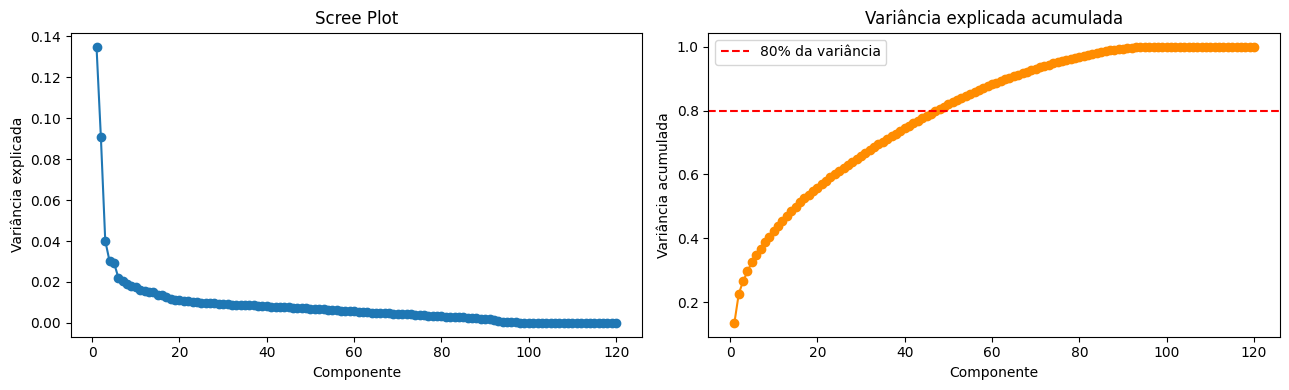

Critério de Kaiser (autovalor > 1): 27 componentes
Componentes necessários para explicar >= 80% da variância: 48

Com n_components=36 a variância explicada acumulada é 32.5%


In [75]:
# Verificação do número de componentes
pca_full = PCA().fit(X_scaled)
explained = pca_full.explained_variance_ratio_
cumulative = np.cumsum(explained)
eigenvalues = pca_full.explained_variance_

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(range(1, len(explained) + 1), explained, 'o-')
axes[0].set_xlabel('Componente')
axes[0].set_ylabel('Variância explicada')
axes[0].set_title('Scree Plot')

axes[1].plot(range(1, len(cumulative) + 1), cumulative, 'o-', color='darkorange')
axes[1].axhline(y=0.80, color='red', linestyle='--', label='80% da variância')
axes[1].set_xlabel('Componente')
axes[1].set_ylabel('Variância acumulada')
axes[1].set_title('Variância explicada acumulada')
axes[1].legend()

plt.tight_layout()
plt.show()

n_kaiser = int((eigenvalues > 1).sum())
n_80pct = int(np.argmax(cumulative >= 0.80) + 1)

print(f"Critério de Kaiser (autovalor > 1): {n_kaiser} componentes")
print(f"Componentes necessários para explicar >= 80% da variância: {n_80pct}")
print(f"\nCom n_components=36 a variância explicada acumulada é "
      f"{cumulative[4]*100:.1f}%")


In [76]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_filtered)

# identificado na célula de scree plot
pca = PCA(n_components=27) 
pca.fit(X_scaled)

# Extração da importância de cada variável (colunas geradas dinamicamente
pc_columns = [f'PC{i}' for i in range(1, pca.n_components_ + 1)]
loadings = pd.DataFrame(pca.components_.T, columns=pc_columns, index=X_filtered.columns)

#### Checagem de sobreposição entre eixos e consolidação do subconjunto final


In [77]:
# Checagem de sobreposição entre as variáveis selecionadas nos diferentes eixos
top_n = 1  # reduzido de 3 para 1 -- com 22 eixos, top_n=3 gerava pouca redução real
           # de dimensionalidade (77 -> 46); com top_n=1, o teto passa a ser 22
selected_by_pc = {
    pc: loadings[pc].abs().sort_values(ascending=False).head(top_n).index.tolist()
    for pc in pc_columns
}

all_selected = [v for lst in selected_by_pc.values() for v in lst]
from collections import Counter
counts = Counter(all_selected)
duplicates = {v: c for v, c in counts.items() if c > 1}

final_vars = sorted(set(all_selected))

print(f"Total de variáveis selecionadas (com repetição): {len(all_selected)}")
print(f"Total de variáveis únicas: {len(final_vars)}")

if duplicates:
    print("\nVariáveis que aparecem em mais de um eixo (redundância entre componentes):")
    for v, c in duplicates.items():
        print(f"  - {v}: aparece em {c} eixos")
else:
    print("\nNenhuma variável repetida entre eixos.")

print(f"\nSubconjunto final de variáveis para o clustering ({len(final_vars)}):")
for v in final_vars:
    print(f"  - {v}")

Total de variáveis selecionadas (com repetição): 27
Total de variáveis únicas: 22

Variáveis que aparecem em mais de um eixo (redundância entre componentes):
  - Goal 2 Score: aparece em 2 eixos
  - Normalizado (0-100): SDG6_8_CLT_DML: aparece em 2 eixos
  - Goal 12 Score: aparece em 3 eixos
  - Normalizado (0-100): SDG11_33_M_TRNS: aparece em 2 eixos

Subconjunto final de variáveis para o clustering (22):
  - Goal 12 Score
  - Goal 13 Score
  - Goal 15 Score
  - Goal 2 Score
  - Normalizado (0-100): SDG10_21_GRV
  - Normalizado (0-100): SDG10_4_ACEQP
  - Normalizado (0-100): SDG10_DIF_FEM_NNN
  - Normalizado (0-100): SDG11_33_M_TRNS
  - Normalizado (0-100): SDG11_4_P_P_SUBN
  - Normalizado (0-100): SDG11_6_NGR_SUBN
  - Normalizado (0-100): SDG16_CRP
  - Normalizado (0-100): SDG17_1_INVST_PB
  - Normalizado (0-100): SDG17_3_P_RC_TRB
  - Normalizado (0-100): SDG3_13_SCD
  - Normalizado (0-100): SDG3_16_M_MAT
  - Normalizado (0-100): SDG3_18_T_M_NT
  - Normalizado (0-100): SDG5_4_P_VRDR


#### Validação: o subconjunto selecionado separa clusters tão bem quanto os componentes PCA?

Selecionar variáveis originais via loading do PCA prioriza interpretabilidade, mas não garante a melhor separação de clusters. Comparamos aqui o *silhouette score* usando o subconjunto final de variáveis versus usar os 5 componentes PCA diretamente, para diferentes números de clusters.


In [78]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

X_final_scaled = StandardScaler().fit_transform(X_filtered[final_vars])
X_pca_scores = pca.transform(X_scaled)  # scores nos 22 componentes já ajustados

resultados = []
for k in range(2, 7):
    km_vars = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_final_scaled)
    km_pca = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_pca_scores)
    sil_vars = silhouette_score(X_final_scaled, km_vars.labels_)
    sil_pca = silhouette_score(X_pca_scores, km_pca.labels_)
    resultados.append({
        'k': k,
        'silhouette_variaveis_selecionadas': round(sil_vars, 4),
        'silhouette_componentes_pca': round(sil_pca, 4)
    })

pd.DataFrame(resultados).set_index('k')

,silhouette_variaveis_selecionadas,silhouette_componentes_pca
k,,
2,0.2181,0.1519
3,0.0654,0.1315
4,0.0718,0.1264
5,0.0778,0.1037
6,0.0798,0.0870


#### Validação de estabilidade: o mesmo padrão de cluster aparece no conjunto de teste?

O split treino/teste foi criado no início do notebook, mas até aqui só o treino tinha sido usado. Como não há rótulo em clustering, o teste aqui não mede acurácia — mede se os clusters encontrados no treino se mantêm coerentes (silhouette parecido) quando o mesmo modelo é aplicado a municípios que ele nunca viu.


In [79]:
# Reaproveita o mesmo scaler e as mesmas variáveis finais selecionadas via PCA
scaler_final = StandardScaler().fit(X_filtered[final_vars])
X_train_final_scaled = scaler_final.transform(X_filtered[final_vars])
X_test_final_scaled = scaler_final.transform(df_test[final_vars])

resultados_estabilidade = []
for k in range(2, 7):
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X_train_final_scaled)
    labels_test = km.predict(X_test_final_scaled)
    sil_train = silhouette_score(X_train_final_scaled, km.labels_)
    sil_test = silhouette_score(X_test_final_scaled, labels_test)
    resultados_estabilidade.append({
        'k': k,
        'silhouette_treino': round(sil_train, 4),
        'silhouette_teste': round(sil_test, 4),
        'diferenca': round(sil_train - sil_test, 4)
    })

pd.DataFrame(resultados_estabilidade).set_index('k')


,silhouette_treino,silhouette_teste,diferenca
k,,,
2,0.2181,0.2110,0.0071
3,0.0654,0.0635,0.0019
4,0.0718,0.0710,0.0008
5,0.0778,0.0763,0.0015
6,0.0798,0.0776,0.0023


In [80]:
print(pca.explained_variance_ratio_)
print(pca.singular_values_)

[0.13501485 0.09079736 0.04018123 0.03005023 0.02941533 0.02212864
 0.02030643 0.01909224 0.01810661 0.01750804 0.01624405 0.01560118
 0.0152901  0.01486289 0.01381148 0.0136956  0.01271518 0.01191827
 0.01116372 0.0110188  0.01074219 0.01059075 0.01037885 0.01012514
 0.0099237  0.00983681 0.00962982]
[250.13820446 205.1284326  136.45859665 118.00846423 116.75516392
 101.26668155  97.0076704   94.06276182  91.60259538  90.07577723
  86.76336779  85.02917185  84.1771984   82.99288994  80.00358426
  79.66724961  76.76275594  74.31833261  71.92730097  71.45891819
  70.55629288  70.05716016  69.35278829  68.49986929  67.8150513
  67.51752256  66.80336889]


Variáveis selecionadas
  - Goal 12 Score:
  - Goal 13 Score: Ação contra a mudança global do clima 
  - Goal 15 Score: Vida Terrestre 
  - Goal 2 Score: Fome zero e agricultura sustentável 
  - Normalizado (0-100): SDG10_21_GRV: Diferença na taxa de gravidez na adolescência entre mães PP e BA
  - Normalizado (0-100): SDG10_4_ACEQP: Acesso a equipamentos da atenção básica à saúde
  - Normalizado (0-100): SDG10_DIF_FEM_NNN: Diferença na taxa de feminicídio de mulheres PPI e BA
  - Normalizado (0-100): SDG11_33_M_TRNS: Mortes no trânsito (100 mil habitantes)
  - Normalizado (0-100): SDG11_4_P_P_SUBN: População residente em favelas e comunidades urbanas (%)
  - Normalizado (0-100): SDG11_6_NGR_SUBN: Percentual da população PP em favelas e comunidades urbanas (%)
  - Normalizado (0-100): SDG16_CRP: Grau de estruturação da política de controle interno e combate à corrupção
  - Normalizado (0-100): SDG17_1_INVST_PB: Investimento público (R$ per capita)
  - Normalizado (0-100): SDG17_3_P_RC_TRB: Total de receitas municipais arrecadadas (%)
  - Normalizado (0-100): SDG3_13_SCD: Total de receitas municipais arrecadadas (%)
  - Normalizado (0-100): SDG3_16_M_MAT: Mortalidade materna (mil nascidos vivos)
  - Normalizado (0-100): SDG3_18_T_M_NT: Mortalidade neonatal (crianças de 0 a 27 dias) (mil nascidas vivas)
  - Normalizado (0-100): SDG5_4_P_VRDR: Presença de vereadoras na Câmara Municipal (%)
  - Normalizado (0-100): SDG5_7_JV_NENT: Diferença percentual entre jovens mulheres e homens que não estudam e nem trabalham (p.p.)
  - Normalizado (0-100): SDG6_1_IN_DRSAI: Doenças relacionadas ao saneamento ambiental inadequado (100 mil habitantes)
  - Normalizado (0-100): SDG6_8_CLT_DML: Índice de tratamento de esgoto (%)
  - Normalizado (0-100): SDG8_2_OCP_INF: População ocupada entre 10 e 17 anos (%)
  - Pontuação Indice ODS 2025